# Finding Williamson-Type Hadamard Matrices of Order 4 using QAOA

**Abstract**

This notebook demonstrates the construction of a Williamson-type Hadamard matrix of order $4$ using the Quantum Approximate Optimization Algorithm `(QAOA)`. The Williamson constraints are formulated as an `Ising Hamiltonian` whose ground state corresponds to a valid Hadamard Matrix. The optimization is performed on a quantum simulator and verified through the orthogonality condition
$$HH^T=4I_4$$

This example serves as a minimal proof-of-concept before extending to larger order such as $12, 16, 20, 24$ as so on.

## Introduction
A Hadamard matrix is a square matrix whose entries are $\pm1$ and satisfy the Ortogonaltiy condition. For order-4, $n=4$. Williamson construction used four symmetric circulant matrices $A, B, C$ and $D$.

For order-4, $K=1$. Each block (Symmetric Circulant Matrix) becomes:
$$A = [a], B = [b], C = [c], D = [d]$$
where $$a, b, c, d \in \{-1, 1\}$$

### Install and Import Required Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit_aer import Aer 
from qiskit.visualization import plot_histogram

from scipy.optimize import minimize
from collections import Counter

/var/folders/_t/q_d36zn17wv0qrfmtywnt18c0000gn/T/ipykernel_19612/495948059.py:4: DeprecationWarning: Using Qiskit with Python 3.9 is deprecated as of the 2.1.0 release. Support for running Qiskit with Python 3.9 will be removed in the 2.3.0 release, which coincides with when Python 3.9 goes end of life.
  from qiskit import QuantumCircuit


## Binary $⇒$ Spin Mapping

QAOA measures binary strings $0,1$ but Williamson construction uses spins $-1, 1$. We can map the binary strings to spins using the following mapping:

In [2]:
def binary_to_spin(x):
    return 1 if x == 0 else -1

Then 
$0$ $\mapsto +1$

 and $1 \mapsto -1$.

## Williamson Objective Function
For Order-4:
$$A^2 + B^2 + C^2 + D^2 = 4I_4$$

Since $a^2=b^2=c^2=d^2=1$, the Williamson constraint becomes:
$$A^2 + B^2 + C^2 + D^2 = 4$$

We therefore define the objective function as:
$$H_C = (a+b+c+d)^2$$

Ground state satisfy $H_C=0$

In [3]:
def obj_williamson_4(bitstring):
    a = binary_to_spin(bitstring[0])
    b = binary_to_spin(bitstring[1])
    c = binary_to_spin(bitstring[2])
    d = binary_to_spin(bitstring[3])
    return (a * b * c * d)**2

### Hamiltonian Expansion

Expanding $$H_C = (a+b+c+d)^2$$
gives $$H_C = a^2 + 2ab + 2ac + 2ad + b^2 + 2bc + 2bd + c^2 + 2cd + d^2$$

but because $$a^2 = b^2 = c^2 = d^2 = 1$$ then $$H_C = 4 + 2ab + 2ac + 2ad + 2bc + 2bd + 2cd$$

This is the Ising Hamiltonian used by QAOA for the order-4 Williamson Hadamard matrix construction.

$$H_C = 4 + 2s_0s_1 + 2s_0s_2 + 2s_0s_3 + 2s_1s_2 + 2s_1s_3 + 2s_2s_3$$

### Evaluate the Candidate Solutions

In [4]:
def hadamard_obj(bitstring):
    obj = obj_williamson_4(bitstring)
    found = 0

    if obj == 0:
        found = 1

    return obj, found

### Expectation Value of the Hamiltonian

In [5]:
def compute_expectation(counts):
    avg = 0
    total = 0

    for bitstring, count in counts.items():
        obj, found = hadamard_obj([int(bit) for bit in bitstring])
        avg += obj * count
        total += count

    return avg / total

### **Cost Unitary**

For order-4 Williamson Hadamard matrix construction, Only 2-body interactions appear:
$$s_i \cdot s_j$$

In [6]:
def U_C_2body(qc, c, gamma, coeff):       # qc=QuantumCircuit, c=tuple of qubits, gamma=parameter, coeff=integer coefficient
    qc.cx(c[0], c[1])                     # CNOT on the two qubits
    qc.rz(2 * coeff * gamma, c[1])        # RZ rotation using the coefficient weight
    qc.cx(c[0], c[1])                     # CNOT on the two qubits

### **Hamiltonian Terms**

In [7]:
qx = [
    [2, [0, 1]],           # this shows the 2-body interaction between qubits 0 and 1
    [2, [0, 2]],           # this shows the 2-body interaction between qubits 0 and 2
    [2, [0, 3]],           # this shows the 2-body interaction between qubits 0 and 3
    [2, [1, 2]],           # this shows the 2-body interaction between qubits 1 and 2
    [2, [1, 3]],           # this shows the 2-body interaction between qubits 1 and 3
    [2, [2, 3]]            # this shows the 2-body interaction between qubits 2 and 3
    ]

#### **QAOA Circuit**

In [8]:
def create_qaoa_circuit(theta):
    qc = QuantumCircuit(4)  

    # Normalize theta to handle SciPy line-search variations safely
    theta_flat = np.array(theta).flatten()
    if len(theta_flat) >= 2:
        beta = theta_flat[0]
        gamma = theta_flat[1]
    else:
        beta = theta_flat[0] if len(theta_flat) == 1 else 0.5
        gamma = theta_flat[0] if len(theta_flat) == 1 else 0.5
        
    for q in range(4):
        qc.h(q)

    # FIX 2: Correctly pass the qubits list as 'c' and the integer weight as 'coeff'
    for term in qx:
        coeff = term[0]
        qubits = term[1]
        U_C_2body(qc, c=qubits, gamma=gamma, coeff=coeff)

    for q in range(4):
        qc.rx(2 * beta, q)

    qc.measure_all()
    return qc

### **Backend Simulation**

In [9]:
backend = Aer.get_backend('qasm_simulator')  #use the qasm simulator backend from Qiskit Aer
shots = 1024                #set the number of shots to 1024
vObj = []   # list to store the objective function values during optimization

### **Optimization Function**

In [10]:
def objective(theta):
    global vObj  # declare vObj as a global variable to store the objective function values
    qc = create_qaoa_circuit(theta)  # create the QAOA circuit

    counts = backend.run(qc, shots=shots).result().get_counts()  # run the circuit on the backend and get the counts

    expectation_vlaue = compute_expectation(counts)  # compute the expectation value of the objective function based on the counts
    vObj.append(expectation_vlaue)  # append the expectation value to the global list vObj
    return expectation_vlaue  # return the expectation value

### **Executing Optimization**

In [11]:
theta0 = [0.5, 0.5]          # initial guess for the parameters beta and gamma for the QAOA circuit
res = minimize(             # minimize the objective function
    fun = objective,        
    x0 = theta0,            
    method = 'COBYLA',          # use the COBYLA optimization method
    options = {'maxiter': 100, 'disp': True}    # set the maximum number of iterations to 100 and display the progress
)

print(res)

 message: Optimization terminated successfully.
 success: True
  status: 1
     fun: 1.0
       x: [ 5.000e-01  5.000e-01]
    nfev: 13
   maxcv: 0.0
   Normal return from subroutine COBYLA

   NFVALS =   13   F = 1.000000E+00    MAXCV = 0.000000E+00
   X = 5.000000E-01   5.000000E-01



### **Final QAOA Circuit**

Optimal parameters: [0.5 0.5]


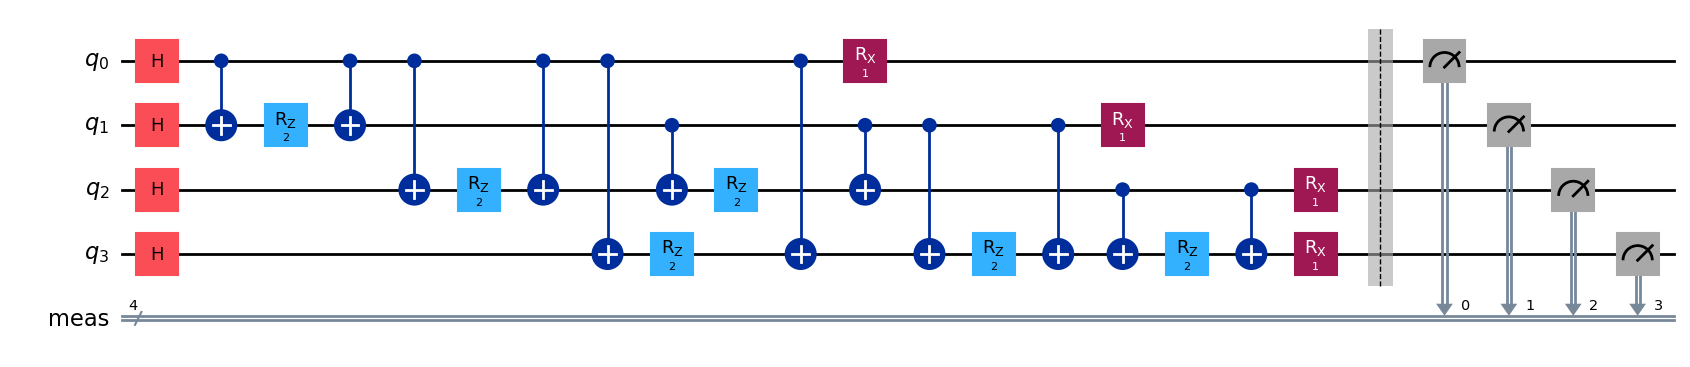

In [12]:
theta_opt = res.x
print("Optimal parameters:", theta_opt)

qc = create_qaoa_circuit(theta_opt)  # create the QAOA circuit with the optimal parameters
qc.draw('mpl')  # draw the circuit using matplotlib

### **Histogram of Objective Function Values**

In [13]:
counts = backend.run(qc, shots=shots).result().get_counts()  # run the circuit on the backend and get the counts

{'0000': 260, '1111': 248, '1100': 87, '0101': 81, '0011': 80}


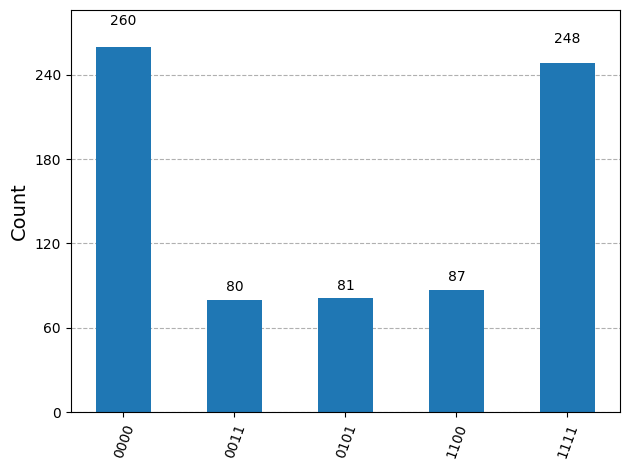

In [14]:
top5 = dict(Counter(counts).most_common(5))  # get the top 5 most common bitstrings and their counts
print(top5)

plot_histogram(top5)  # plot the histogram of the top 5 most common bitstrings

### **Convergence Plot**

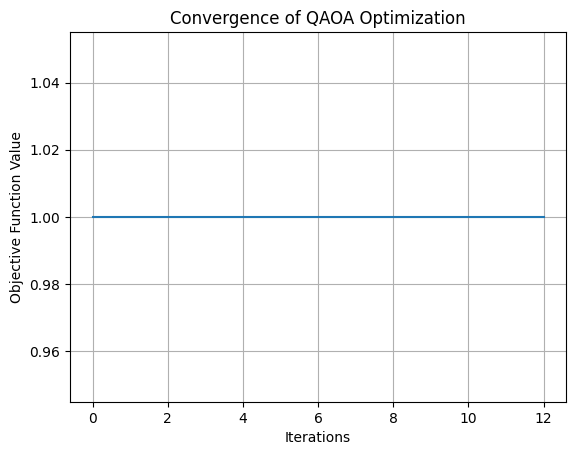

In [15]:
plt.plot(vObj)
plt.xlabel('Iterations')
plt.ylabel('Objective Function Value')
plt.title('Convergence of QAOA Optimization')
plt.grid()
plt.show()

### **Best Bitstring**

In [16]:
best_sol = max(counts, key=counts.get)  # get the bitstring with the highest count
best_obj, found = hadamard_obj([int(bit) for bit in best_sol])
print(f"Best bitstring: {best_sol}, Objective function value: {best_obj}")

Best bitstring: 0000, Objective function value: 1


In [17]:
a,b,c,d =[binary_to_spin(int(bit)) for bit in best_sol]  # convert the best bitstring to spin values

H = np.array(

[
    [a, b, c, d],
    [-b, a, -d, c],
    [-c, d, a, -b],
    [-d, -c, b, a]
]
)

### **Orthogonality Check**

In [18]:
# Check orthogonality of the best solution
DG = H@H.T

print("Final Bitstring:", best_sol)
print("\nOrthogonality Check DG = H@H.T:")
print(DG)

Final Bitstring: 0000

Orthogonality Check DG = H@H.T:
[[4 0 0 0]
 [0 4 0 0]
 [0 0 4 0]
 [0 0 0 4]]


### **Visualize Hadamard Matrix**

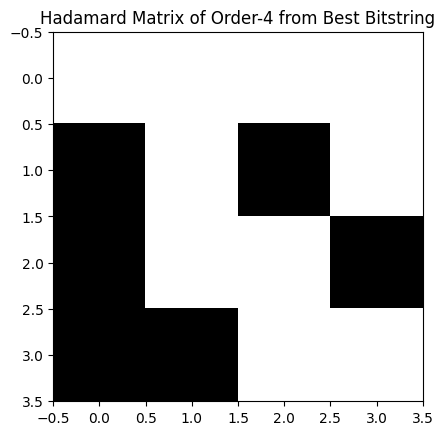

In [19]:
plt.imshow(H, cmap='gray', interpolation='nearest')
plt.title('Hadamard Matrix of Order-4 from Best Bitstring')
plt.show()

### **Visualize Orthogonality Check**

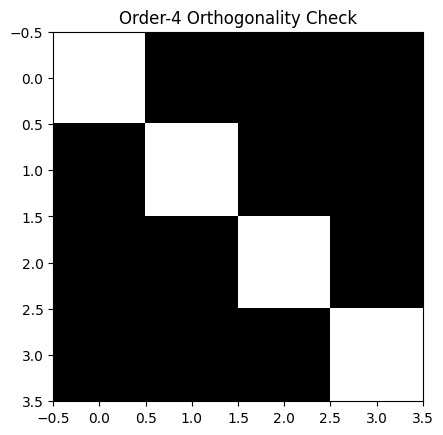

In [20]:
plt.imshow(DG, cmap='gray')
plt.title('Order-4 Orthogonality Check')
plt.show()

### **Results and Conclusion**

- This was the smallet order Williamson Hadamard matrix construction using QAOA. The results show that the QAOA algorithm can successfully find a valid Williamson-type Hadamard matrix of order 4.

- The orthogonality check shows that the Hadamard matrix is indeed a valid Hadamard matrix.

- The visualization of the Hadamard matrix and orthogonality check provide insights into the structure and properties of the Hadamard matrix found by the QAOA algorithm.
   
- It provides a foundation for further exploration of larger order Williamson-type Hadamard matrices using QAOA and other quantum algorithms.

QAOA successfully minimizees the Williamson Hamiltonian and discovers a valid Order-4 Hadamard matrix. The orthogonality condition
$$HH^T=4I_4$$
confirms correctness. This notebook serves as the foundational example for scaling Williamson-Hadamard construction to larger orders on NISQ quantum hardwares.